In [540]:
import numpy as np
from numpy import sin, cos
import matplotlib.pyplot as plt
from numpy.linalg import inv
from scipy.linalg import sqrtm

In [541]:
def noise(cov):
    return np.random.multivariate_normal(
        mean=np.zeros_like(cov[0]),
        cov=cov
    )

In [542]:
def get_ellipse_points(mu: np.ndarray, Sigma: np.ndarray, P=0.95, N=200):
    t = np.linspace(0, 2*np.pi, N)
    circle = np.vstack((np.cos(t), np.sin(t)))
    rhs = -2*np.log(1-P)
    ellipse = np.sqrt(rhs) * circle
    scaled_ellipse = sqrtm(Sigma) @ ellipse # circle -> ellipse
    return scaled_ellipse + mu.reshape(2,1)

# Problem 1

## EKF

In [543]:
def f_1(X, u, dt):
    p,a,b = X
    p_dot = -a*p + b*u
    X_dot = np.array([p_dot, 0, 0])
    return X + X_dot*dt

def g_1(X):
    return X[0]

In [544]:
def get_A_1(X, u, dt):
    p,a,b, = X
    # return dt * np.array([-a, -p, u])
    return np.array([
        [1-dt*a, -dt*p, dt*u],
        [0, 1, 0],
        [0, 0, 1]
    ])

def get_C_1():
    return np.array([1, 0, 0]).reshape((1,3))

In [545]:
a = 0.5
b = 2

X0 = np.array([5, a, b])

def get_u(t):
    return sin(t)

Q_true = np.diag([0.1, 0, 0])
R_true = np.eye(1)*0.1

dt = 0.1
t_max = 100
N = int(t_max/dt)
t_arr = np.linspace(0, t_max, N+1)

In [546]:
mu0 = np.array([0, 0, 0])
Sigma0 = np.eye(3)*10

Q_ekf = np.diag([0.1, 0.01, 0.01])
R_ekf = np.eye(1)*0.1

In [547]:
# np.array([noise(R_true), 0, 0])
# np.array([noise(R_true).reshape(1)[0], 0, 0])
noise(Q_true)

array([-0.0672323,  0.       ,  0.       ])

In [548]:
X_arr = np.zeros((N+1, 3))
Y_arr = np.zeros((N+1, 1))

mu_arr = np.zeros((N+1, 3))
Sigma_arr = np.zeros((N+1, 3, 3))

X_arr[0] = X0
Y_arr[0] = X0[0] + noise(R_true)

mu_arr[0] = mu0
Sigma_arr[0] = Sigma0

t_arr = dt*np.arange(N+1)

for i in range(N):
    t = t_arr[i]
    # True
    X = X_arr[i]
    u = get_u(t)
    
    X_arr[i+1] = f_1(X_arr[i], u, dt) + noise(Q_true)
    Y_arr[i] = g_1(X_arr[i]) + noise(R_true)

    # Measure


    # EKF Predict
    mu_pred = f_1(mu_arr[i], u, dt)
    A = get_A_1(mu_arr[i], u, dt)
    Sigma_predict = A @ Sigma_arr[i] @ A.T + Q_ekf

    

    # EKF Update
    C = get_C_1()
    K = Sigma_predict @ C.T @ inv(C @ Sigma_predict @ C.T + R_ekf)
    mu_arr[i+1] = mu_pred + K @ (Y_arr[i] - g_1(mu_pred))

    Sigma_arr[i+1] = Sigma_predict - K @ C @ Sigma_predict


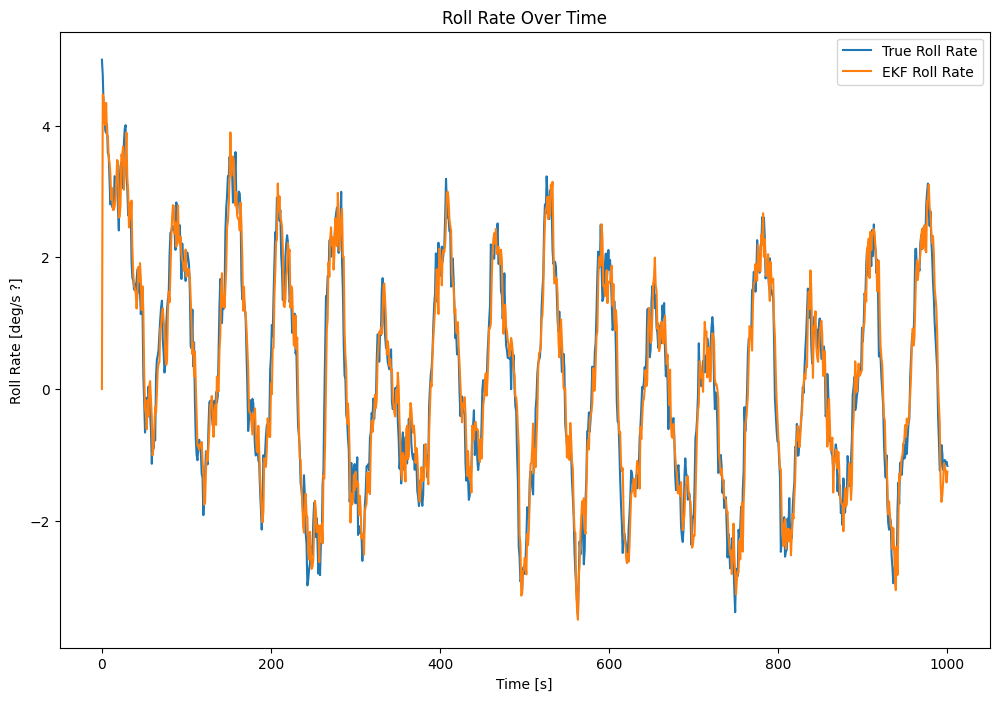

In [549]:
plt.figure(figsize=(12,8))
plt.plot(X_arr[:,0], label="True Roll Rate")
plt.plot(mu_arr[:,0], label="EKF Roll Rate")

plt.title("Roll Rate Over Time")
plt.xlabel("Time [s]")
plt.ylabel("Roll Rate [deg/s ?]")
plt.legend()
plt.show()

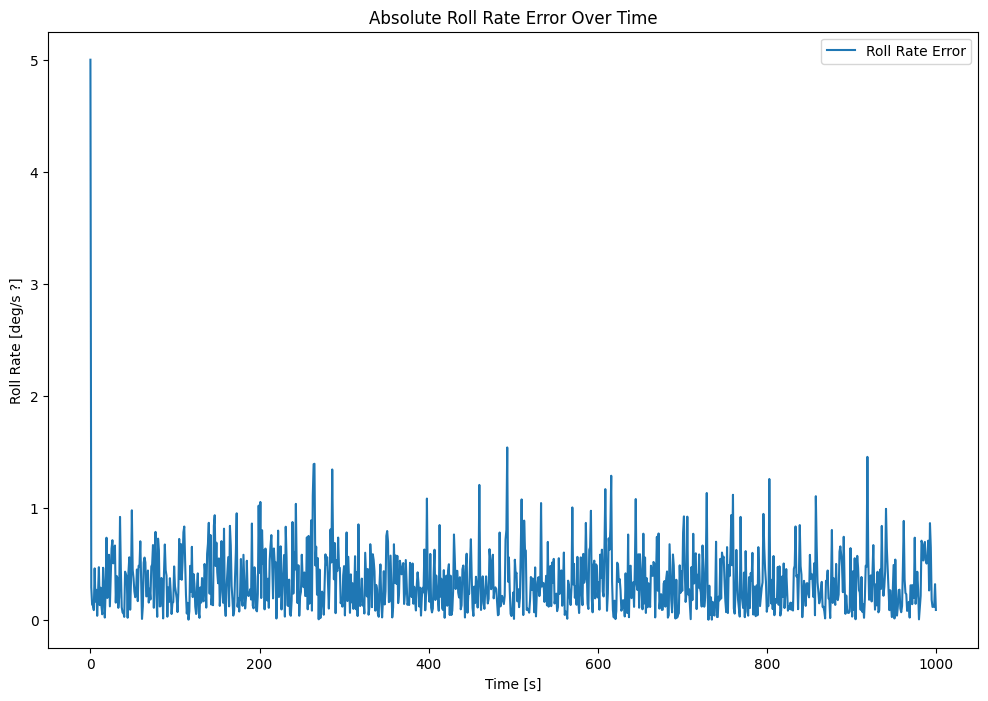

In [550]:
plt.figure(figsize=(12,8))
plt.plot(abs(X_arr[:,0] - mu_arr[:,0]), label="Roll Rate Error")
plt.title("Absolute Roll Rate Error Over Time")
plt.xlabel("Time [s]")
plt.ylabel("Roll Rate [deg/s ?]")
plt.legend()
plt.show()

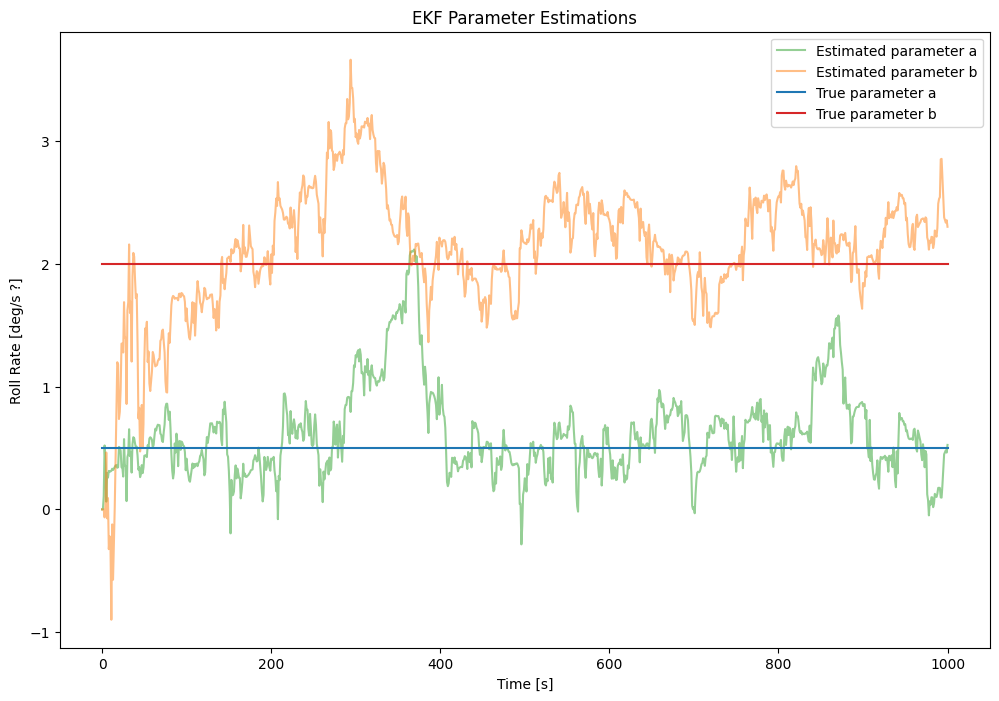

In [551]:
plt.figure(figsize=(12,8))
plt.plot(mu_arr[:,1],label="Estimated parameter a", alpha=0.5, color="tab:green")
plt.plot(mu_arr[:,2],label="Estimated parameter b", alpha=0.5, color="tab:orange")
plt.plot(X_arr[:,1],label="True parameter a", color="tab:blue")
plt.plot(X_arr[:,2],label="True parameter b", color="tab:red")
plt.title("EKF Parameter Estimations")
plt.xlabel("Time [s]")
plt.ylabel("Roll Rate [deg/s ?]")
plt.legend()
plt.show()

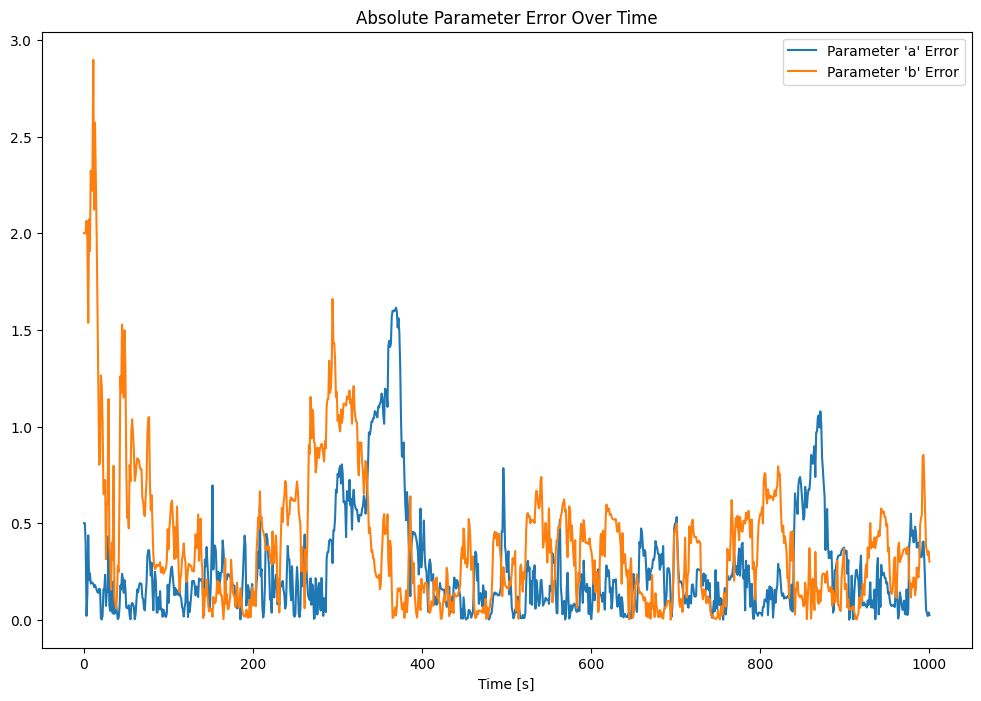

In [552]:
plt.figure(figsize=(12,8))
plt.plot(abs(mu_arr[:,1] - X_arr[:,1]), label="Parameter 'a' Error")
plt.plot(abs(mu_arr[:,2] - X_arr[:,2]), label="Parameter 'b' Error")
plt.title("Absolute Parameter Error Over Time")
plt.xlabel("Time [s]")
# plt.ylabel("Roll Rate [deg/s ?]")
plt.legend()
plt.show()


# Problem 3

In [553]:
def f_3(X, u, dt):
    x, y, Theta = X
    s, phi = u

    x_next = x + dt*s*cos(Theta)
    y_next = y + dt*s*sin(Theta)
    Theta_next = Theta + dt*phi

    return np.array([
        x_next, y_next, Theta_next
    ])

def g_3(X, positions):
    P = X[0:2]
    Theta = X[2]

    A = np.array([
        [cos(Theta), sin(Theta)],
        [-sin(Theta), cos(Theta)]])

    measurements = [(A @ (position - P)).T
        for position in positions]

    return np.asarray(measurements).reshape((8))

X = np.array([3,3,3])
measurement_locations = np.array([
    [0, 0], [10, 0], [10, 10], [0, 10]
])

In [554]:
def get_A_3(X, u, dt):
    _, _, Theta = X[0:3]
    s, _ = u

    A = np.array([
        [1, 0, -dt*s*sin(Theta)],
        [0, 1,  dt*s*cos(Theta)],
        [0, 0,        1        ]
    ])
    return A

def get_C_3(X, positions):
    x, y, Theta = X

    c = cos(Theta)
    s = sin(Theta)

    rows = []
    for pos in positions:
        C = np.array([
            [-c, -s, -s*(pos[0] - x) + c*(pos[1] - y)],
            [s, -c, -c*(pos[0] - x) - s*(pos[1] - y)]
        ])

        rows.append(C)

    return np.vstack(rows)


X = np.array([10,30,40])
measurement_locations = np.array([
    [0, 0], [10, 0], [10, 10], [0, 10]
])

# get_C(X, measurement_locations)

In [555]:
def get_u(t):
    return np.array([0.5, sin(2*t)])

In [556]:
SEED = 273

In [557]:
measurement_locations = np.array([
    [0, 0], [10, 0], [10, 10], [0, 10]
])

dt = 0.5
TIMESTEPS = 100
Q_robot = np.eye(3) * 0.1 * dt
R_M = np.eye(8) * 0.25 # for 8 measurements

np.random.seed(SEED)
X0_robot = np.array([1,1,0])

In [558]:
mu0_pos = np.random.multivariate_normal(
        mean=X0_robot,
        cov=np.eye(3)
    )
# Sigma0 = np.eye(3)* 1e5
Sigma0_pos = np.eye(3)

## Part b

In [559]:
# np.random.seed(SEED)
np.random.seed(273)

X_arr = np.zeros((TIMESTEPS+1, 3))
Y_arr = np.zeros((TIMESTEPS+1, 8))

mu_arr = np.zeros((TIMESTEPS+1, 3))
Sigma_arr = np.zeros((TIMESTEPS+1, 3, 3))

X_arr[0] = X0_robot
Y_arr[0] = g_3(X0_robot, measurement_locations) + noise(R_M)

mu_arr[0] = mu0_pos
Sigma_arr[0] = Sigma0_pos

for i in range(TIMESTEPS):
    t = i * dt
    
    # True
    X = X_arr[i]
    u = get_u(t)
    
    X_arr[i+1] = f_3(X, u, dt) + noise(Q_robot)
    # print(g_prob3(X, measurement_locations))
    Y_arr[i] = g_3(X, measurement_locations) + noise(R_M)
    # break

    # Measure


    # EKF Predict
    mu_pred = f_3(mu_arr[i], u, dt)

    A = get_A_3(mu_arr[i], u, dt)
    Sigma_predict = A @ Sigma_arr[i] @ A.T + Q_robot

    

    # EKF Update
    C = get_C_3(mu_pred, measurement_locations)

    # print(C.shape)
    # print(Sigma_predict.shape)
    K = Sigma_predict @ C.T @ inv(C @ Sigma_predict @ C.T + R_M)
    mu_arr[i+1] = mu_pred + K @ (Y_arr[i] - g_3(mu_pred, measurement_locations))

    Sigma_arr[i+1] = Sigma_predict - K @ C @ Sigma_predict

# plt.figure(figsize=(12,8))
# plt.plot(X_arr[:,0], X_arr[:,1], label="Actual trajectory")
# plt.plot(mu_arr[:,0], mu_arr[:,1], label="Measured trajectory")
# # plt.plot(X_arr[:,0], label="EKF Y Pos")

# plt.title("Position over time")
# plt.xlabel("Time [s]")
# plt.legend()
# plt.show()

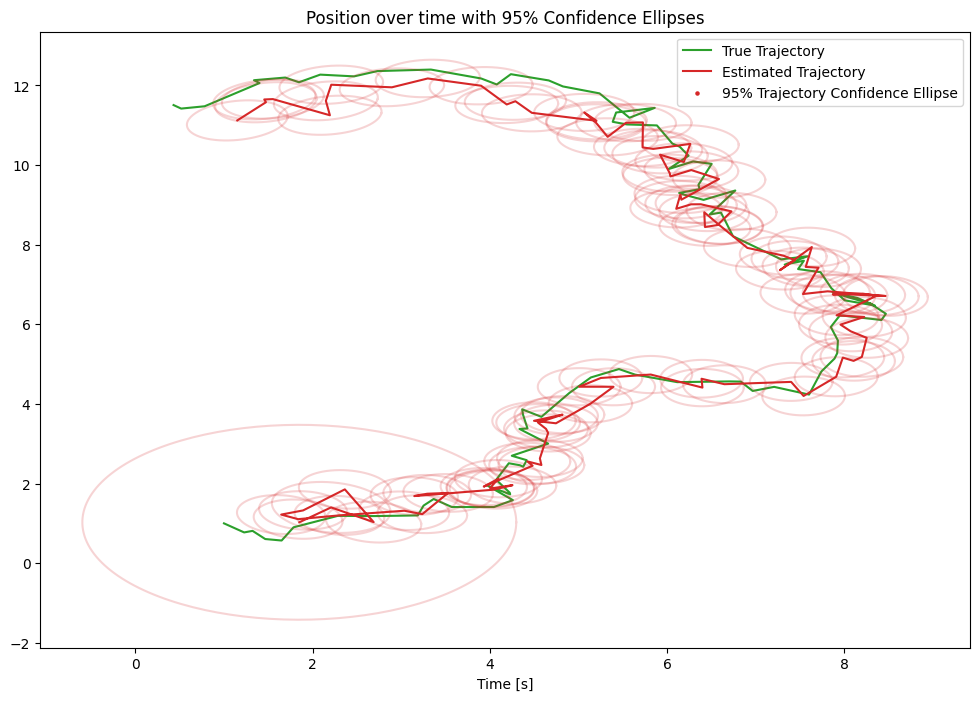

In [560]:
plt.figure(figsize=(12,8))

plt.plot([], [], color="tab:green", label="True Trajectory")[0]
plt.plot([], [], label="Estimated Trajectory", color="tab:red")[0]
plt.scatter([], [], color='tab:red', zorder=2, s=5, label="95% Trajectory Confidence Ellipse")



plt.plot(X_arr[:,0], X_arr[:,1], color="tab:green")
plt.plot(mu_arr[:,0], mu_arr[:,1], color="tab:red")

for mu, sigma in zip(mu_arr, Sigma_arr):
    position = mu[0:2]
    position_sigma = sigma[0:2, 0:2]
    factor = 1
    
    ellipse_x, ellipse_y = get_ellipse_points(position, position_sigma)
    plt.plot(ellipse_x, ellipse_y, color='tab:red', zorder=2, alpha=0.2)


plt.title("Position over time with 95% Confidence Ellipses")
plt.xlabel("Time [s]")
plt.legend()
plt.show()

## part c

In [561]:
def g_3_map(positions, robot_state):
    P = robot_state[0:2]
    Theta = robot_state[2]

    A_T = np.array([
        [cos(Theta), sin(Theta)],
        [-sin(Theta), cos(Theta)]])
    
    measurements = []

    for i in range(0, len(positions), 2):

        measurement = positions[i:i+2]
        measurements.append(A_T @ (measurement - P))

    return np.hstack(measurements)


def get_C_3_map(robot_state, n_landmarks):
    _, _, Theta = robot_state

    A = np.array([
        [cos(Theta), sin(Theta)],
        [-sin(Theta), cos(Theta)]])


    C = np.zeros((2*n_landmarks,2*n_landmarks))

    for i in range(0, 2*n_landmarks, 2):

        C[i:i+2, i:i+2] = A

    return C



In [562]:
est_positions0 = np.zeros(8)
mu0_features = np.zeros(8)
Sigma0_features = np.eye(8) * 1e5
Q_F = np.zeros((8,8))

In [563]:
X_arr = np.zeros((TIMESTEPS+1, 3))
Y_arr = np.zeros((TIMESTEPS+1, 8))

mu_arr = np.zeros((TIMESTEPS+1, 8))
Sigma_arr = np.zeros((TIMESTEPS+1, 8, 8))

X_arr[0] = X0_robot
Y_arr[0] = g_3_map(measurement_locations.reshape((8)), X0_robot) + noise(R_M)

mu_arr[0] = mu0_features
Sigma_arr[0] = Sigma0_features

n_landmarks = len(measurement_locations)

for i in range(TIMESTEPS):
    t = i * dt
    
    # Trajectory
    u = get_u(t)
    
    X_arr[i+1] = f_3(X_arr[i], u, dt)
    # print(g_prob3(X, measurement_locations))
    Y_arr[i] = g_3_map(measurement_locations.reshape((8)), X_arr[i]) + noise(R_M)

    # EKF Predict
    mu_pred = mu_arr[i]
    Sigma_predict = Sigma_arr[i] + Q_F

    

    # EKF Update
    C = get_C_3_map(X_arr[i], n_landmarks)

    K = Sigma_predict @ C.T @ inv(C @ Sigma_predict @ C.T + R_M)
    mu_arr[i+1] = mu_pred + K @ (Y_arr[i] - g_3_map(mu_pred, X_arr[i]))

    Sigma_arr[i+1] = Sigma_predict - K @ C @ Sigma_predict

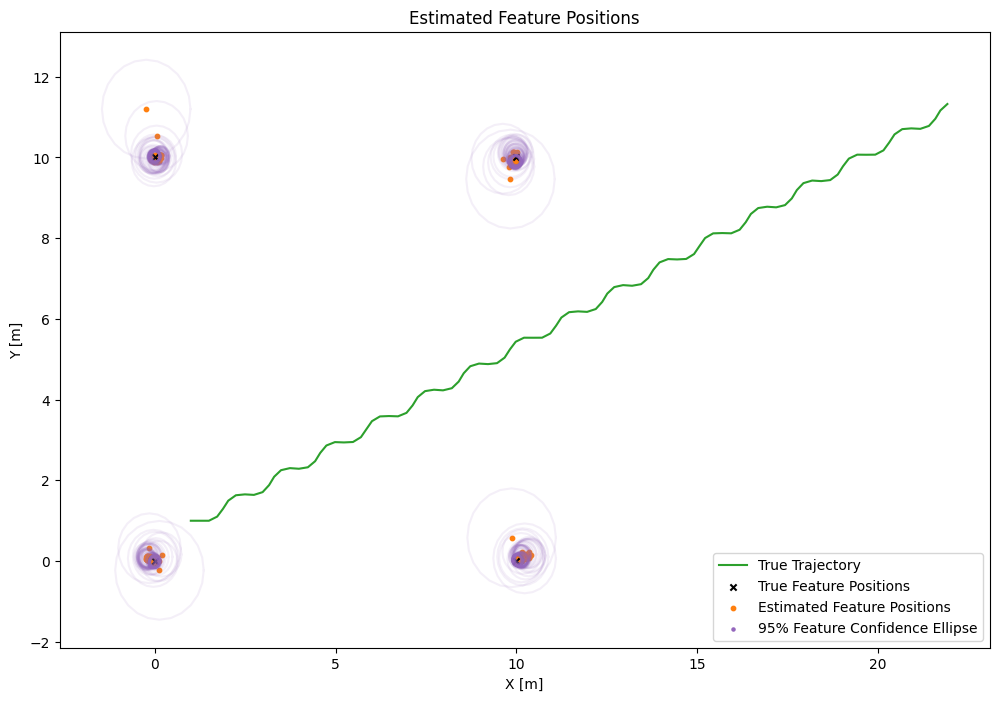

In [564]:
plt.figure(figsize=(12,8))

plt.plot([], [], color="tab:green", label="True Trajectory")[0]
plt.scatter([], [], label="True Feature Positions", s=20, color="k", marker="x")
plt.scatter([], [], label="Estimated Feature Positions", s=10, color="tab:orange")
plt.scatter([], [], color='tab:purple', s=5, label=r"95% Feature Confidence Ellipse")

for mu, sigma in zip(mu_arr[1:], Sigma_arr[1:]):

    for i in range(0, 8, 2):
        position = mu[i:i+2]
        position_sigma = sigma[i:i+2, i:i+2]
        factor = 1
        ellipse_x, ellipse_y = get_ellipse_points(position, position_sigma, N=25)
        plt.plot(ellipse_x, ellipse_y, color='tab:purple',alpha=0.1)

    


plt.scatter(mu_arr[:,0], mu_arr[:,1], s=10, color="tab:orange")
plt.scatter(mu_arr[:,2], mu_arr[:,3], s=10, color="tab:orange")
plt.scatter(mu_arr[:,4], mu_arr[:,5], s=10, color="tab:orange")
plt.scatter(mu_arr[:,6], mu_arr[:,7], s=10, color="tab:orange")

plt.scatter(measurement_locations[:,0], measurement_locations[:,1], marker="x", s=20, color="k")
plt.plot(X_arr[:,0], X_arr[:,1], color="tab:green")



plt.title("Estimated Feature Positions")
plt.xlabel("X [m]")
plt.ylabel("Y [m]")
plt.legend()
plt.show()

## part d

In [565]:
def f_SLAM(state: np.ndarray, u: np.ndarray, dt: float):
    x, y, Theta = state[0:3]
    s, phi = u

    x_next = x + dt*s*cos(Theta)
    y_next = y + dt*s*sin(Theta)
    Theta_next = Theta + dt*phi

    state_next = state.copy()
    state_next[0:3] = [x_next, y_next, Theta_next]

    return state_next

def g_SLAM(state: np.ndarray):
    """4 Landmarks"""
    P = state[0:2]
    Theta = state[2]
    positions = state[3:11].reshape((4,2))

    A = np.array([
        [cos(Theta), sin(Theta)],
        [-sin(Theta), cos(Theta)]])

    measurements = [A @ (position - P)
        for position in positions]

    return np.array(measurements).reshape((8))


In [566]:
measurement_locations = np.array([
    [0, 0], [10, 0], [10, 10], [0, 10]
])

In [567]:
def get_A_SLAM(state: np.ndarray, u: np.ndarray, dt: float):
    """4 Landmarks"""
    _, _, Theta = state[0:3]
    s, _ = u


    A = np.eye(11)
    A[0:3, 0:3] = np.array([
        [1, 0, -dt*s*sin(Theta)],
        [0, 1,  dt*s*cos(Theta)],
        [0, 0,        1        ]
    ])
    return A

def get_C_SLAM(state: np.ndarray):
    """4 Landmarks"""
    x, y, Theta = state[0:3]
    positions = state[3:11].reshape((4,2))

    c = cos(Theta)
    s = sin(Theta)

    C_robot = []
    for pos in positions:
        row = np.array([
            [-c, -s, -s*(pos[0] - x) + c*(pos[1] - y)],
            [s, -c, -c*(pos[0] - x) - s*(pos[1] - y)]
        ])

        C_robot.append(row)
    C_robot = np.vstack(C_robot)

    R = np.array([
        [c, s],
        [-s, c]]
    )

    n_landmarks = 4
    C_landmarks = np.zeros((2*n_landmarks,2*n_landmarks))

    for i in range(0, 2*n_landmarks, 2):

        C_landmarks[i:i+2, i:i+2] = R

    C = np.hstack((C_robot, C_landmarks))

    return C
    

X_test = np.array([10,30,40])
measurement_locations = np.array([
    [0, 0], [10, 0], [10, 10], [0, 10]
])

X_large = np.hstack((X_test, measurement_locations.reshape(8)))

print(get_C_SLAM(X_large).shape)

(8, 11)


In [568]:
dt = 0.5
TIMESTEPS = 100
measurement_locations = np.array([
    [0, 0], [10, 0], [10, 10], [0, 10]
])
SEED = 273

In [569]:
Q_SLAM = np.zeros((11,11))
Q_SLAM[0:3, 0:3] = np.eye(3) * 0.1 * dt
R_SLAM = np.eye(8) * 0.25 # for 8 measurements

P0 = [1,1,0]
truth0 = np.hstack((P0, measurement_locations.reshape(8)))

In [570]:
mu_pos0 = [1,1,0]
mu_loc_0 = np.array([
    [0,0],
    [0,0],
    [0,0],
    [0,0]
])
mu0 = np.hstack((mu_pos0, mu_loc_0.reshape(8)))
Sigma0 = np.eye(11)
Sigma0[3:11, 3:11] *= 1e5

In [571]:
np.random.seed(SEED)
truth_arr = np.zeros((TIMESTEPS+1, 11))
meas_arr = np.zeros((TIMESTEPS+1, 8))

mu_arr = np.zeros((TIMESTEPS+1, 11))
Sigma_arr = np.zeros((TIMESTEPS+1, 11, 11))

truth_arr[0] = truth0
meas_arr[0] = g_SLAM(truth0) + noise(R_SLAM)


mu_arr[0] = mu0
Sigma_arr[0] = Sigma0

n_landmarks = 4

for i in range(TIMESTEPS):
    t = i * dt

    # Input
    u = get_u(t)
    
    # Truth
    truth_arr[i+1] = f_SLAM(truth_arr[i], u, dt) + noise(Q_SLAM)
    meas_arr[i] = g_SLAM(truth_arr[i]) + noise(R_SLAM)

    # EKF Predict
    mu_pred = f_SLAM(mu_arr[i], u, dt)
    A = get_A_SLAM(mu_arr[i], u, dt)
    Sigma_pred = A @ Sigma_arr[i] @ A.T + Q_SLAM

    # EKF Update
    C = get_C_SLAM(mu_pred)

    K = Sigma_pred @ C.T @ inv(C @ Sigma_pred @ C.T + R_SLAM)
    mu_arr[i+1] = mu_pred + K @ (meas_arr[i] - g_SLAM(mu_pred))

    Sigma_arr[i+1] = Sigma_pred - K @ C @ Sigma_pred

#     C_F = get_C_3_map(mu_robot_arr[i], n_landmarks)
#     features = Sigma_features_predict @ C_F.T @ inv(C_F @ Sigma_features_predict @ C_F.T + R_M)
#     mu_features_arr[i+1] = mu_features_pred + features @ (meas_Y_arr[i] - g_3_map(mu_features_pred, mu_robot_arr[i]))
#     Sigma_features_arr[i+1] = Sigma_features_predict - features @ C_F @ Sigma_features_predict

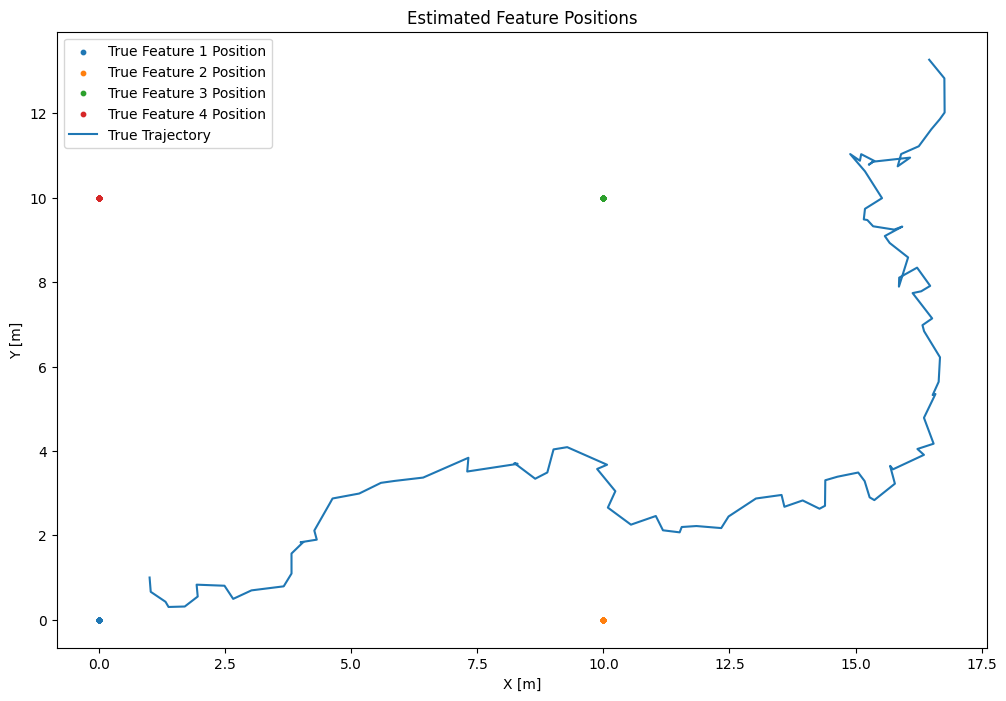

In [572]:
plt.figure(figsize=(12,8))
plt.scatter(truth_arr[:,3], truth_arr[:,4], label="True Feature 1 Position", s=10)
plt.scatter(truth_arr[:,5], truth_arr[:,6], label="True Feature 2 Position", s=10)
plt.scatter(truth_arr[:,7], truth_arr[:,8], label="True Feature 3 Position", s=10)
plt.scatter(truth_arr[:,9], truth_arr[:,10], label="True Feature 4 Position", s=10)

plt.plot(truth_arr[:,0], truth_arr[:,1], label="True Trajectory")
    

plt.title("Estimated Feature Positions")
plt.xlabel("X [m]")
plt.ylabel("Y [m]")
plt.legend()
plt.show()

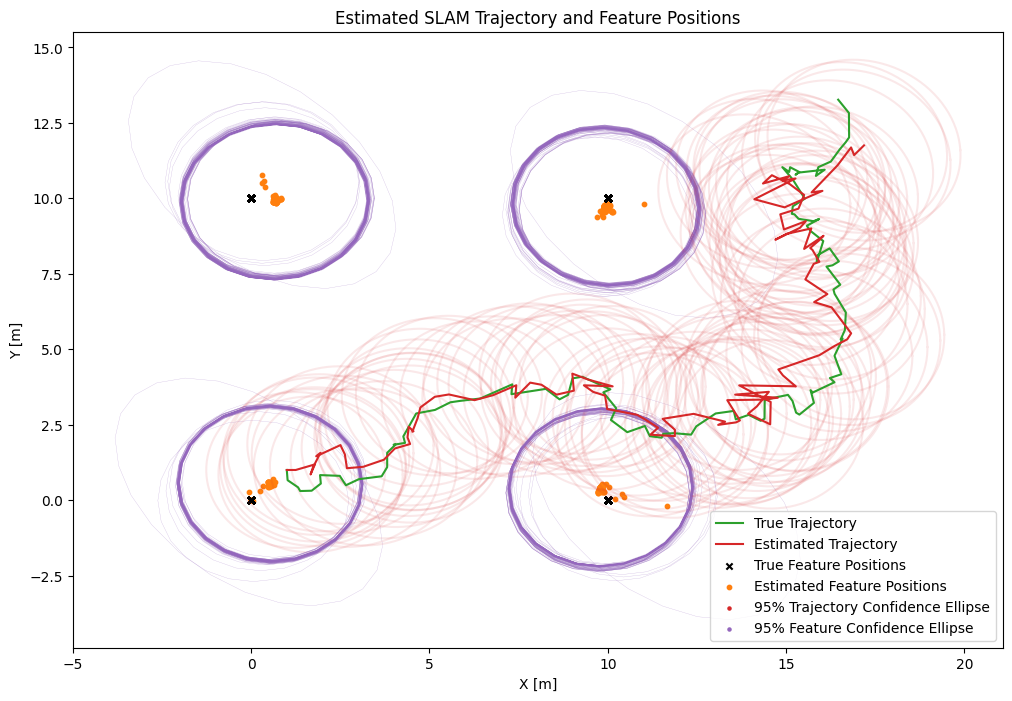

In [573]:
plt.figure(figsize=(12,8))


plt.plot([], [], color="tab:green", label="True Trajectory")[0]
plt.plot([], [], label="Estimated Trajectory", color="tab:red")[0]
plt.scatter([], [], label="True Feature Positions", s=20, color="k", marker="x")
plt.scatter([], [], label="Estimated Feature Positions", s=10, color="tab:orange")
plt.scatter([], [], color='tab:red', zorder=2, s=5, label="95% Trajectory Confidence Ellipse")
plt.scatter([], [], color='tab:purple', s=5, label=r"95% Feature Confidence Ellipse")


for i, (mu, sigma) in enumerate(zip(mu_arr[1:], Sigma_arr[1:])):
    position = mu[0:2]
    position_sigma = sigma[0:2, 0:2]
    factor = 1
    
    ellipse_x, ellipse_y = get_ellipse_points(position, position_sigma)

    plt.plot(ellipse_x, ellipse_y, color='tab:red', zorder=2, alpha=0.1)

    for i in range(3, 11, 2):
        position = mu[i:i+2]
        position_sigma = sigma[i:i+2, i:i+2]
        factor = 1
        ellipse_x, ellipse_y = get_ellipse_points(position, position_sigma, N=25)
        plt.plot(ellipse_x, ellipse_y, color='tab:purple', linewidth=0.2, alpha=0.5)

    


plt.plot(truth_arr[:,0], truth_arr[:,1], color="tab:green")
plt.plot(mu_arr[:,0], mu_arr[:,1], color="tab:red")

plt.scatter(mu_arr[:,3], mu_arr[:,4], s=10, color="tab:orange")
plt.scatter(mu_arr[:,5], mu_arr[:,6], s=10, color="tab:orange")
plt.scatter(mu_arr[:,7], mu_arr[:,8], s=10, color="tab:orange")
plt.scatter(mu_arr[:,9], mu_arr[:,10], s=10, color="tab:orange")

plt.scatter(truth_arr[:,3], truth_arr[:,4], s=20, color="k", marker="x")
plt.scatter(truth_arr[:,5], truth_arr[:,6], s=20, color="k", marker="x")
plt.scatter(truth_arr[:,7], truth_arr[:,8], s=20, color="k", marker="x")
plt.scatter(truth_arr[:,9], truth_arr[:,10], s=20, color="k", marker="x")

plt.title("Estimated SLAM Trajectory and Feature Positions")
plt.xlabel("X [m]")
plt.ylabel("Y [m]")
plt.legend()
plt.show()